In [1]:
# ==========================================
# BANK MARKETING FUNNEL ANALYSIS
# Google Colab
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
import io

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Upload the CSV file
uploaded = files.upload()

# Automatically identify the uploaded CSV
file_name = list(uploaded.keys())[0]

# Read CSV
df = pd.read_csv(
    io.BytesIO(uploaded[file_name]),
    sep=None,
    engine='python'
)

print("Dataset loaded successfully!")
print("File:", file_name)
print("Shape:", df.shape)

df.head()

Saving bank-full.csv to bank-full.csv
Dataset loaded successfully!
File: bank-full.csv
Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
# Display number of rows and columns
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

Number of rows: 45211
Number of columns: 17

Column Names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   4

In [4]:
# Statistical summary
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


In [5]:
# Check first 10 records
df.head(10)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no


In [6]:
# Missing values
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


In [7]:
# Missing-value percentage
missing_percentage = (
    df.isnull().sum() / len(df) * 100
).sort_values(ascending=False)

missing_percentage

,0
age,0.0
job,0.0
marital,0.0
education,0.0
default,0.0
balance,0.0
housing,0.0
loan,0.0
contact,0.0
day,0.0


In [8]:
# Check duplicate records
duplicates = df.duplicated().sum()

print("Number of duplicate records:", duplicates)

Number of duplicate records: 0


In [9]:
# Remove duplicates
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (45211, 17)


In [10]:
# Remove unnecessary spaces from column names
df.columns = df.columns.str.strip()

# Remove leading/trailing spaces from categorical columns
categorical_columns = df.select_dtypes(include='object').columns

for col in categorical_columns:
    df[col] = df[col].astype(str).str.strip().str.lower()

print("Data cleaning completed.")

Data cleaning completed.


In [11]:
# Check unique values of categorical columns

for col in df.select_dtypes(include='object').columns:
    print("\n", col)
    print(df[col].unique())


 job
['management' 'technician' 'entrepreneur' 'blue-collar' 'unknown'
 'retired' 'admin.' 'services' 'self-employed' 'unemployed' 'housemaid'
 'student']

 marital
['married' 'single' 'divorced']

 education
['tertiary' 'secondary' 'unknown' 'primary']

 default
['no' 'yes']

 housing
['yes' 'no']

 loan
['no' 'yes']

 contact
['unknown' 'cellular' 'telephone']

 month
['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'jan' 'feb' 'mar' 'apr' 'sep']

 poutcome
['unknown' 'failure' 'other' 'success']

 y
['no' 'yes']


In [12]:
# Target variable distribution

print("Subscription (y) distribution:")
print(df['y'].value_counts())

Subscription (y) distribution:
y
no     39922
yes     5289
Name: count, dtype: int64


In [13]:
# Percentage of customers who subscribed

subscription_percentage = (
    df['y'].value_counts(normalize=True) * 100
)

print(subscription_percentage)

y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


In [14]:
total_leads = len(df)

customers = (df['y'] == 'yes').sum()

conversion_rate = customers / total_leads * 100

print("Total Leads:", total_leads)
print("Customers:", customers)
print("Conversion Rate:", round(conversion_rate, 2), "%")

Total Leads: 45211
Customers: 5289
Conversion Rate: 11.7 %


In [15]:
# Funnel stages supported by the dataset

funnel = pd.DataFrame({
    'Stage': [
        'Leads Contacted',
        'Customers Converted'
    ],
    'Count': [
        total_leads,
        customers
    ]
})

funnel

,Stage,Count
0,Leads Contacted,45211
1,Customers Converted,5289


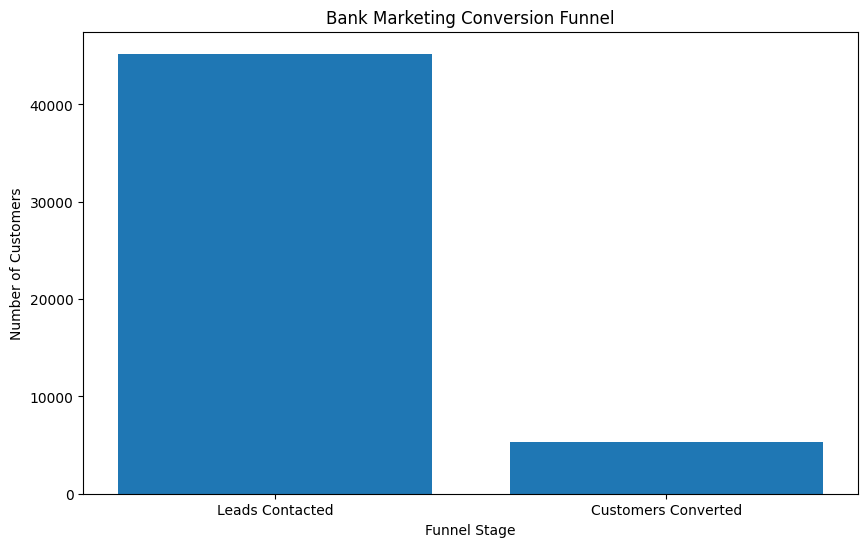

In [16]:
# Funnel chart

plt.figure(figsize=(10, 6))

plt.bar(
    funnel['Stage'],
    funnel['Count']
)

plt.title('Bank Marketing Conversion Funnel')
plt.xlabel('Funnel Stage')
plt.ylabel('Number of Customers')

plt.show()

In [17]:
lead_to_customer_rate = customers / total_leads * 100

print("Lead-to-Customer Conversion Rate:",
      round(lead_to_customer_rate, 2), "%")

print("Lead-to-Customer Drop-off Rate:",
      round(100 - lead_to_customer_rate, 2), "%")

Lead-to-Customer Conversion Rate: 11.7 %
Lead-to-Customer Drop-off Rate: 88.3 %


In [18]:
job_analysis = df.groupby('job').agg(
    total_leads=('y', 'count'),
    customers=('y', lambda x: (x == 'yes').sum())
)

job_analysis['conversion_rate'] = (
    job_analysis['customers'] /
    job_analysis['total_leads'] * 100
)

job_analysis = job_analysis.sort_values(
    'conversion_rate',
    ascending=False
)

job_analysis

,total_leads,customers,conversion_rate
job,,,
student,938,269,28.678038
retired,2264,516,22.791519
unemployed,1303,202,15.502686
management,9458,1301,13.755551
admin.,5171,631,12.202669
self-employed,1579,187,11.842939
unknown,288,34,11.805556
technician,7597,840,11.056996
services,4154,369,8.883004


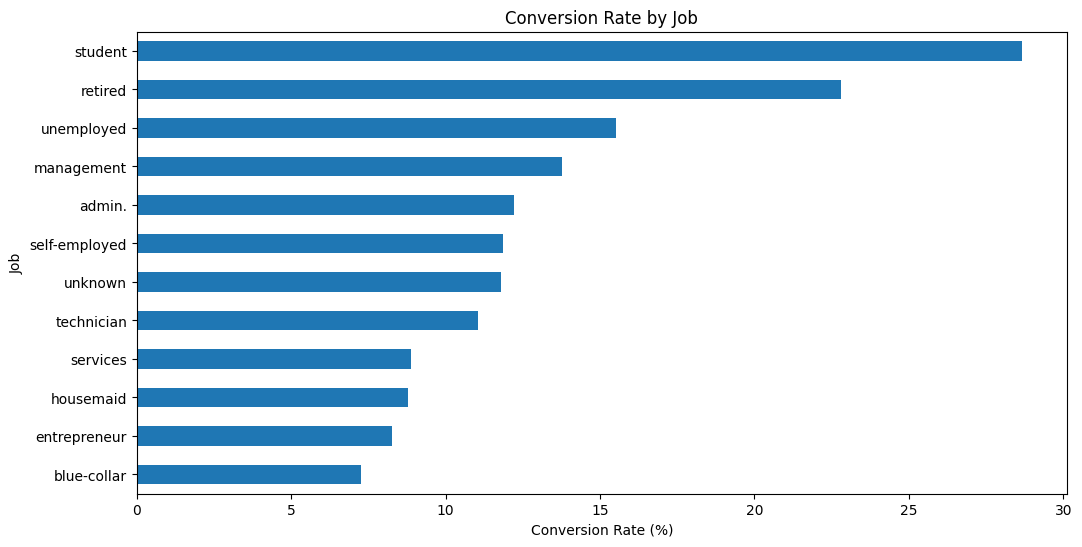

In [19]:
# Plot conversion rate by job

plt.figure(figsize=(12, 6))

job_analysis['conversion_rate'].sort_values().plot(
    kind='barh'
)

plt.title('Conversion Rate by Job')
plt.xlabel('Conversion Rate (%)')
plt.ylabel('Job')

plt.show()

In [20]:
education_analysis = df.groupby('education').agg(
    total_leads=('y', 'count'),
    customers=('y', lambda x: (x == 'yes').sum())
)

education_analysis['conversion_rate'] = (
    education_analysis['customers'] /
    education_analysis['total_leads'] * 100
)

education_analysis

,total_leads,customers,conversion_rate
education,,,
primary,6851,591,8.626478
secondary,23202,2450,10.559435
tertiary,13301,1996,15.006390
unknown,1857,252,13.570275


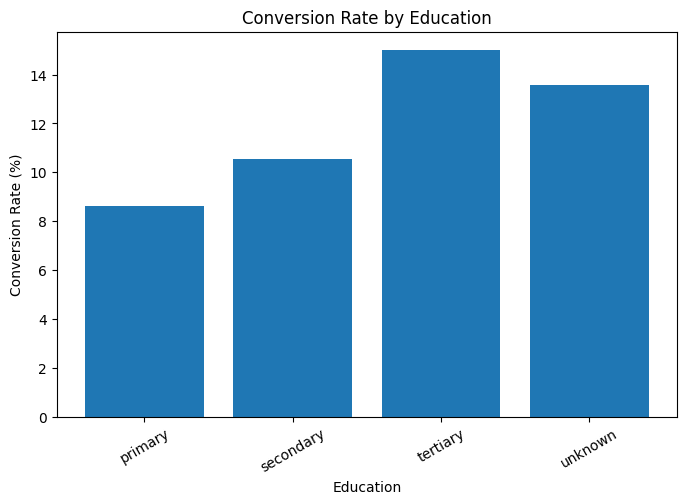

In [21]:
plt.figure(figsize=(8, 5))

plt.bar(
    education_analysis.index,
    education_analysis['conversion_rate']
)

plt.title('Conversion Rate by Education')
plt.xlabel('Education')
plt.ylabel('Conversion Rate (%)')

plt.xticks(rotation=30)

plt.show()

In [22]:
marital_analysis = df.groupby('marital').agg(
    total_leads=('y', 'count'),
    customers=('y', lambda x: (x == 'yes').sum())
)

marital_analysis['conversion_rate'] = (
    marital_analysis['customers'] /
    marital_analysis['total_leads'] * 100
)

marital_analysis

,total_leads,customers,conversion_rate
marital,,,
divorced,5207,622,11.945458
married,27214,2755,10.123466
single,12790,1912,14.949179


In [23]:
housing_analysis = df.groupby('housing').agg(
    total_leads=('y', 'count'),
    customers=('y', lambda x: (x == 'yes').sum())
)

housing_analysis['conversion_rate'] = (
    housing_analysis['customers'] /
    housing_analysis['total_leads'] * 100
)

housing_analysis

,total_leads,customers,conversion_rate
housing,,,
no,20081,3354,16.702355
yes,25130,1935,7.699960


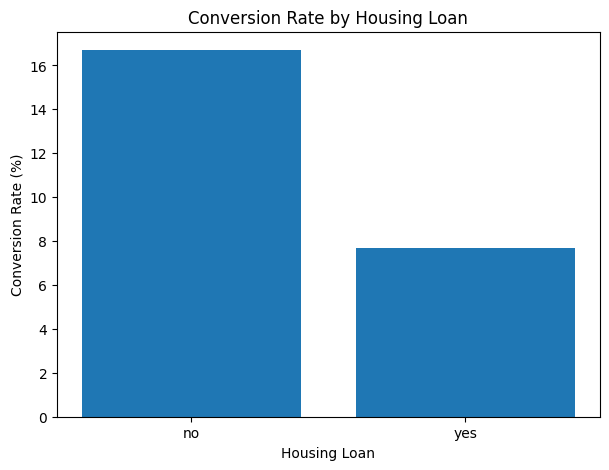

In [24]:
plt.figure(figsize=(7, 5))

plt.bar(
    housing_analysis.index,
    housing_analysis['conversion_rate']
)

plt.title('Conversion Rate by Housing Loan')
plt.xlabel('Housing Loan')
plt.ylabel('Conversion Rate (%)')

plt.show()

In [25]:
loan_analysis = df.groupby('loan').agg(
    total_leads=('y', 'count'),
    customers=('y', lambda x: (x == 'yes').sum())
)

loan_analysis['conversion_rate'] = (
    loan_analysis['customers'] /
    loan_analysis['total_leads'] * 100
)

loan_analysis

,total_leads,customers,conversion_rate
loan,,,
no,37967,4805,12.655727
yes,7244,484,6.681391


In [26]:
contact_analysis = df.groupby('contact').agg(
    total_leads=('y', 'count'),
    customers=('y', lambda x: (x == 'yes').sum())
)

contact_analysis['conversion_rate'] = (
    contact_analysis['customers'] /
    contact_analysis['total_leads'] * 100
)

contact_analysis = contact_analysis.sort_values(
    'conversion_rate',
    ascending=False
)

contact_analysis

,total_leads,customers,conversion_rate
contact,,,
cellular,29285,4369,14.918900
telephone,2906,390,13.420509
unknown,13020,530,4.070661


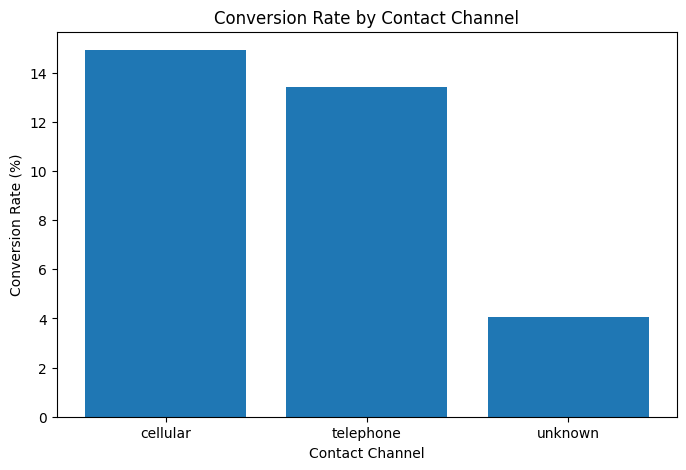

In [27]:
plt.figure(figsize=(8, 5))

plt.bar(
    contact_analysis.index,
    contact_analysis['conversion_rate']
)

plt.title('Conversion Rate by Contact Channel')
plt.xlabel('Contact Channel')
plt.ylabel('Conversion Rate (%)')

plt.show()

In [28]:
month_analysis = df.groupby('month').agg(
    total_leads=('y', 'count'),
    customers=('y', lambda x: (x == 'yes').sum())
)

month_analysis['conversion_rate'] = (
    month_analysis['customers'] /
    month_analysis['total_leads'] * 100
)

month_analysis

,total_leads,customers,conversion_rate
month,,,
apr,2932,577,19.679400
aug,6247,688,11.013286
dec,214,100,46.728972
feb,2649,441,16.647792
jan,1403,142,10.121169
jul,6895,627,9.093546
jun,5341,546,10.222805
mar,477,248,51.991614
may,13766,925,6.719454


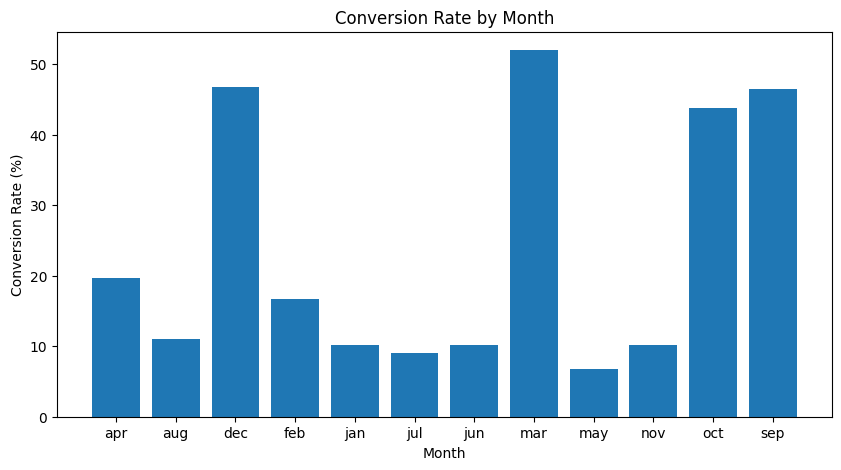

In [29]:
plt.figure(figsize=(10, 5))

plt.bar(
    month_analysis.index,
    month_analysis['conversion_rate']
)

plt.title('Conversion Rate by Month')
plt.xlabel('Month')
plt.ylabel('Conversion Rate (%)')

plt.show()

In [30]:
campaign_analysis = df.groupby('campaign').agg(
    total_leads=('y', 'count'),
    customers=('y', lambda x: (x == 'yes').sum())
)

campaign_analysis['conversion_rate'] = (
    campaign_analysis['customers'] /
    campaign_analysis['total_leads'] * 100
)

campaign_analysis.head(20)

,total_leads,customers,conversion_rate
campaign,,,
1,17544,2561,14.597583
2,12505,1401,11.203519
3,5521,618,11.193624
4,3522,317,9.000568
5,1764,139,7.879819
6,1291,92,7.126259
7,735,47,6.394558
8,540,32,5.925926
9,327,21,6.422018


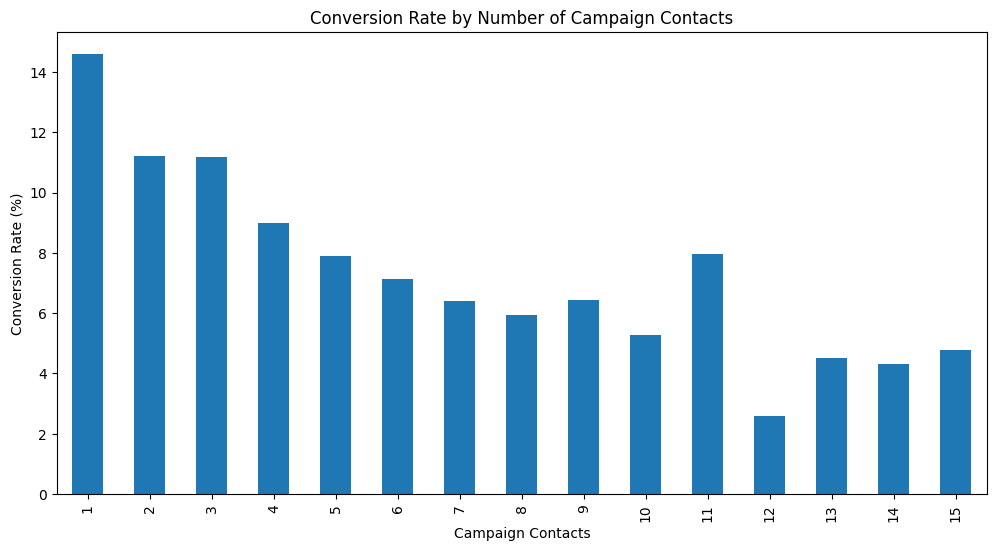

In [31]:
plt.figure(figsize=(12, 6))

campaign_analysis.head(15)['conversion_rate'].plot(
    kind='bar'
)

plt.title('Conversion Rate by Number of Campaign Contacts')
plt.xlabel('Campaign Contacts')
plt.ylabel('Conversion Rate (%)')

plt.show()

In [32]:
# Average call duration for converted and non-converted customers

duration_analysis = df.groupby('y')['duration'].mean()

print("Average Call Duration:")
print(duration_analysis)

Average Call Duration:
y
no     221.182806
yes    537.294574
Name: duration, dtype: float64


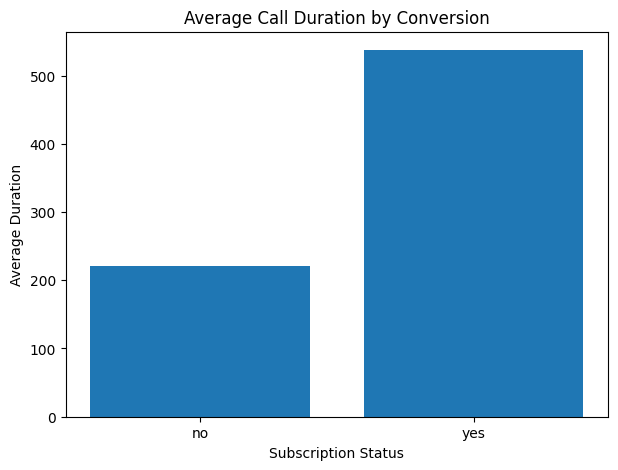

In [33]:
plt.figure(figsize=(7, 5))

plt.bar(
    duration_analysis.index,
    duration_analysis.values
)

plt.title('Average Call Duration by Conversion')
plt.xlabel('Subscription Status')
plt.ylabel('Average Duration')

plt.show()

In [34]:
# Create age groups

df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=[
        '18-25',
        '26-35',
        '36-45',
        '46-55',
        '56-65',
        '65+'
    ]
)

age_analysis = df.groupby(
    'age_group',
    observed=False
).agg(
    total_leads=('y', 'count'),
    customers=('y', lambda x: (x == 'yes').sum())
)

age_analysis['conversion_rate'] = (
    age_analysis['customers'] /
    age_analysis['total_leads'] * 100
)

age_analysis

,total_leads,customers,conversion_rate
age_group,,,
18-25,1336,320,23.952096
26-35,15571,1869,12.003083
36-45,13856,1301,9.389434
46-55,9548,893,9.352744
56-65,4149,586,14.123885
65+,751,320,42.609854


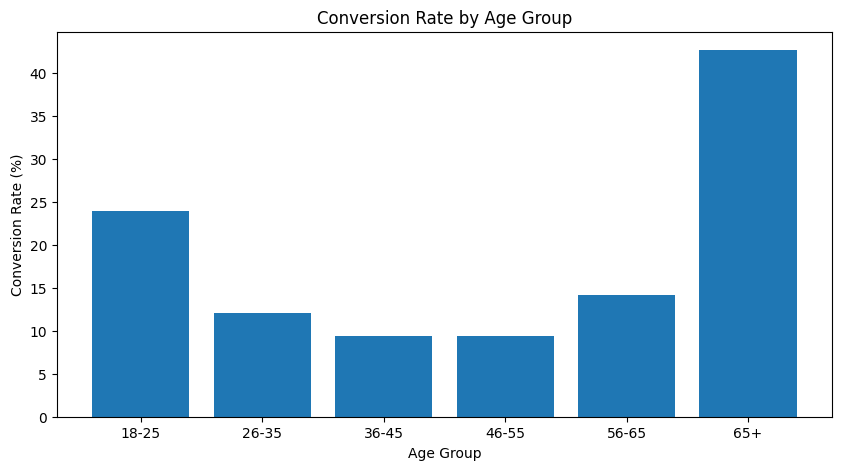

In [35]:
plt.figure(figsize=(10, 5))

plt.bar(
    age_analysis.index.astype(str),
    age_analysis['conversion_rate']
)

plt.title('Conversion Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Conversion Rate (%)')

plt.show()

In [36]:
poutcome_analysis = df.groupby('poutcome').agg(
    total_leads=('y', 'count'),
    customers=('y', lambda x: (x == 'yes').sum())
)

poutcome_analysis['conversion_rate'] = (
    poutcome_analysis['customers'] /
    poutcome_analysis['total_leads'] * 100
)

poutcome_analysis = poutcome_analysis.sort_values(
    'conversion_rate',
    ascending=False
)

poutcome_analysis

,total_leads,customers,conversion_rate
poutcome,,,
success,1511,978,64.725347
other,1840,307,16.684783
failure,4901,618,12.609671
unknown,36959,3386,9.161503


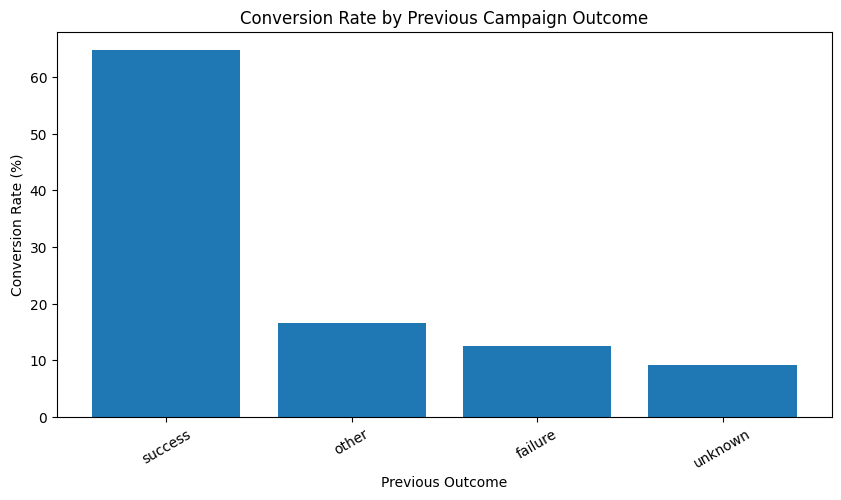

In [37]:
plt.figure(figsize=(10, 5))

plt.bar(
    poutcome_analysis.index,
    poutcome_analysis['conversion_rate']
)

plt.title('Conversion Rate by Previous Campaign Outcome')
plt.xlabel('Previous Outcome')
plt.ylabel('Conversion Rate (%)')

plt.xticks(rotation=30)

plt.show()

In [38]:
default_analysis = df.groupby('default').agg(
    total_leads=('y', 'count'),
    customers=('y', lambda x: (x == 'yes').sum())
)

default_analysis['conversion_rate'] = (
    default_analysis['customers'] /
    default_analysis['total_leads'] * 100
)

default_analysis

,total_leads,customers,conversion_rate
default,,,
no,44396,5237,11.796108
yes,815,52,6.380368


In [39]:
# ==========================================
# KEY PERFORMANCE INDICATORS
# ==========================================

total_records = len(df)
total_conversions = (df['y'] == 'yes').sum()
total_non_conversions = (df['y'] == 'no').sum()

overall_conversion = (
    total_conversions / total_records * 100
)

average_age = df['age'].mean()
average_balance = df['balance'].mean()
average_duration = df['duration'].mean()

print("====================================")
print("       BANK MARKETING KPI REPORT")
print("====================================")

print(f"Total Leads             : {total_records:,}")
print(f"Converted Customers     : {total_conversions:,}")
print(f"Non-Converted Leads     : {total_non_conversions:,}")
print(f"Conversion Rate         : {overall_conversion:.2f}%")
print(f"Average Customer Age    : {average_age:.2f}")
print(f"Average Account Balance : {average_balance:.2f}")
print(f"Average Call Duration   : {average_duration:.2f}")

print("====================================")

       BANK MARKETING KPI REPORT
Total Leads             : 45,211
Converted Customers     : 5,289
Non-Converted Leads     : 39,922
Conversion Rate         : 11.70%
Average Customer Age    : 40.94
Average Account Balance : 1362.27
Average Call Duration   : 258.16


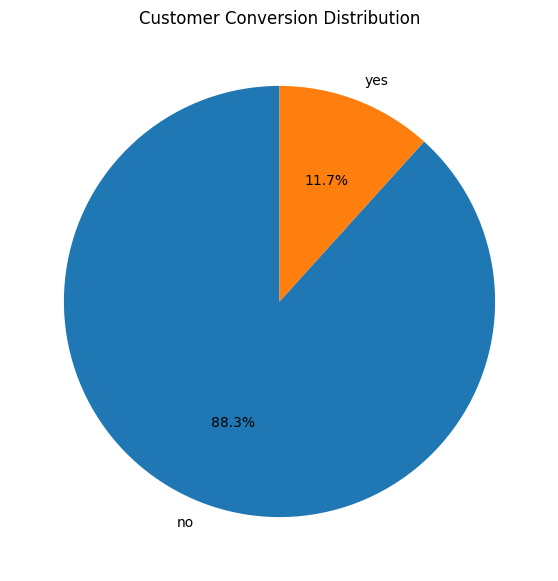

In [40]:
conversion_counts = df['y'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    conversion_counts.values,
    labels=conversion_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Conversion Distribution')

plt.show()

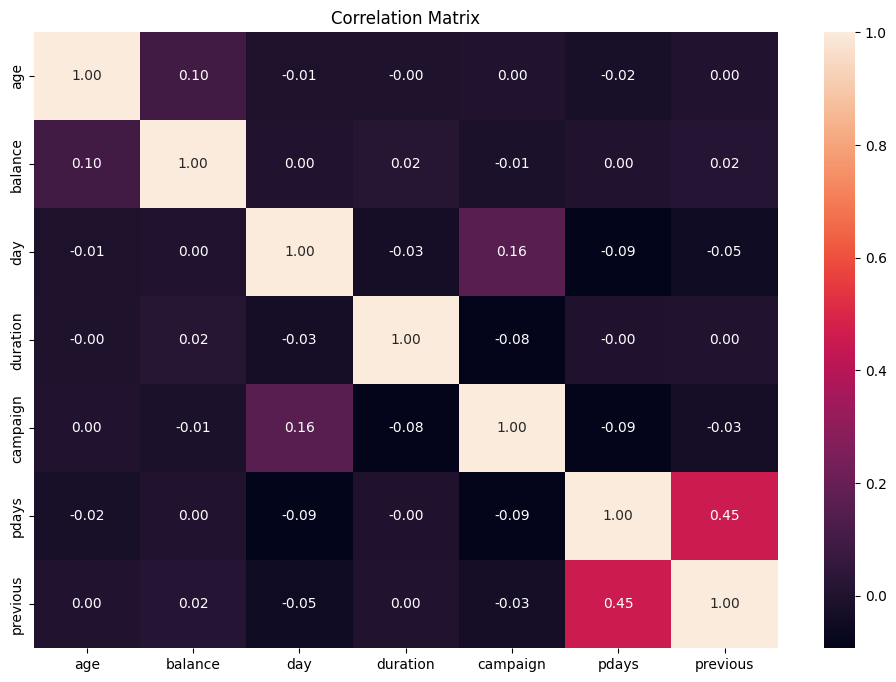

In [41]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns

correlation = df[numeric_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f'
)

plt.title('Correlation Matrix')

plt.show()

In [42]:
# Best contact channel

best_channel = contact_analysis[
    'conversion_rate'
].idxmax()

best_channel_rate = contact_analysis.loc[
    best_channel,
    'conversion_rate'
]

print("Best Performing Contact Channel:", best_channel)
print(
    "Conversion Rate:",
    round(best_channel_rate, 2),
    "%"
)

Best Performing Contact Channel: cellular
Conversion Rate: 14.92 %


In [43]:
best_month = month_analysis[
    'conversion_rate'
].idxmax()

best_month_rate = month_analysis.loc[
    best_month,
    'conversion_rate'
]

print("Best Performing Month:", best_month)
print(
    "Conversion Rate:",
    round(best_month_rate, 2),
    "%"
)

Best Performing Month: mar
Conversion Rate: 51.99 %


In [44]:
best_previous_outcome = poutcome_analysis[
    'conversion_rate'
].idxmax()

best_previous_rate = poutcome_analysis.loc[
    best_previous_outcome,
    'conversion_rate'
]

print(
    "Best Previous Campaign Outcome:",
    best_previous_outcome
)

print(
    "Conversion Rate:",
    round(best_previous_rate, 2),
    "%"
)

Best Previous Campaign Outcome: success
Conversion Rate: 64.73 %


In [45]:
# Identify groups with above-average conversion rates

average_conversion = overall_conversion

high_performing_jobs = job_analysis[
    job_analysis['conversion_rate'] > average_conversion
]

print("Jobs with above-average conversion:")
display(high_performing_jobs)

Jobs with above-average conversion:


,total_leads,customers,conversion_rate
job,,,
student,938,269,28.678038
retired,2264,516,22.791519
unemployed,1303,202,15.502686
management,9458,1301,13.755551
admin.,5171,631,12.202669
self-employed,1579,187,11.842939
unknown,288,34,11.805556


In [46]:
campaign_analysis['drop_off_rate'] = (
    100 - campaign_analysis['conversion_rate']
)

campaign_analysis.sort_values(
    'drop_off_rate',
    ascending=False
).head(15)

,total_leads,customers,conversion_rate,drop_off_rate
campaign,,,,
33,6,0,0.0,100.0
34,5,0,0.0,100.0
35,4,0,0.0,100.0
36,4,0,0.0,100.0
37,2,0,0.0,100.0
38,3,0,0.0,100.0
31,12,0,0.0,100.0
30,8,0,0.0,100.0
25,22,0,0.0,100.0


In [47]:
print("==========================================")
print("           KEY BUSINESS INSIGHTS")
print("==========================================")

print(
    f"1. Overall lead-to-customer conversion "
    f"rate is {overall_conversion:.2f}%."
)

print(
    f"2. The best contact channel is "
    f"'{best_channel}' with a conversion rate "
    f"of {best_channel_rate:.2f}%."
)

print(
    f"3. The best performing month is "
    f"'{best_month}' with a conversion rate "
    f"of {best_month_rate:.2f}%."
)

print(
    f"4. The previous campaign outcome with "
    f"the highest conversion rate is "
    f"'{best_previous_outcome}'."
)

print(
    "5. Campaign performance should be monitored "
    "to identify stages with high customer drop-off."
)

print(
    "6. Marketing resources can be focused on "
    "channels and customer segments with higher "
    "conversion rates."
)

print("==========================================")

           KEY BUSINESS INSIGHTS
1. Overall lead-to-customer conversion rate is 11.70%.
2. The best contact channel is 'cellular' with a conversion rate of 14.92%.
3. The best performing month is 'mar' with a conversion rate of 51.99%.
4. The previous campaign outcome with the highest conversion rate is 'success'.
5. Campaign performance should be monitored to identify stages with high customer drop-off.
6. Marketing resources can be focused on channels and customer segments with higher conversion rates.


In [48]:
print("==========================================")
print("             RECOMMENDATIONS")
print("==========================================")

print("1. Focus marketing efforts on high-converting "
      "contact channels.")

print("2. Study the characteristics of customers who "
      "successfully converted.")

print("3. Reduce repeated contacts when additional "
      "campaign contacts show low conversion.")

print("4. Use successful previous campaign outcomes "
      "to identify high-quality leads.")

print("5. Concentrate campaigns during periods with "
      "higher conversion rates.")

print("6. Monitor conversion rate regularly using "
      "a KPI dashboard.")

print("7. Investigate high drop-off groups and improve "
      "the communication strategy.")

print("8. Segment customers by age, job, education, "
      "loan status and previous campaign outcome.")

print("==========================================")

             RECOMMENDATIONS
1. Focus marketing efforts on high-converting contact channels.
2. Study the characteristics of customers who successfully converted.
3. Reduce repeated contacts when additional campaign contacts show low conversion.
4. Use successful previous campaign outcomes to identify high-quality leads.
5. Concentrate campaigns during periods with higher conversion rates.
6. Monitor conversion rate regularly using a KPI dashboard.
7. Investigate high drop-off groups and improve the communication strategy.
8. Segment customers by age, job, education, loan status and previous campaign outcome.


In [49]:
summary = pd.DataFrame({
    'KPI': [
        'Total Leads',
        'Converted Customers',
        'Non-Converted Leads',
        'Conversion Rate',
        'Average Age',
        'Average Balance',
        'Average Call Duration'
    ],
    'Value': [
        total_records,
        total_conversions,
        total_non_conversions,
        round(overall_conversion, 2),
        round(average_age, 2),
        round(average_balance, 2),
        round(average_duration, 2)
    ]
})

summary

,KPI,Value
0,Total Leads,45211.00
1,Converted Customers,5289.00
2,Non-Converted Leads,39922.00
3,Conversion Rate,11.70
4,Average Age,40.94
5,Average Balance,1362.27
6,Average Call Duration,258.16


In [50]:
# Save important analysis tables

job_analysis.to_csv(
    'job_conversion_analysis.csv'
)

contact_analysis.to_csv(
    'contact_conversion_analysis.csv'
)

month_analysis.to_csv(
    'month_conversion_analysis.csv'
)

campaign_analysis.to_csv(
    'campaign_conversion_analysis.csv'
)

poutcome_analysis.to_csv(
    'previous_outcome_analysis.csv'
)

summary.to_csv(
    'bank_marketing_kpi_summary.csv',
    index=False
)

print("Analysis files saved successfully!")

Analysis files saved successfully!


In [51]:
from google.colab import files

files.download(
    'bank_marketing_kpi_summary.csv'
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>